# ISLR Ch 4.7 #6, 8, 9 & 10

6.<br>(a)

![6a](problem-a.jpeg)

(b)

![6a](problem-b.jpeg)

8.

![8](problem-8.jpeg)
![8-a](problem-8-a.jpeg)
![8-b](problem-8-b.jpeg)

10)

[1] "Year"      "Lag1"      "Lag2"      "Lag3"      "Lag4"      "Lag5"     
[7] "Volume"    "Today"     "Direction"

[1] 1089    9

      Year           Lag1               Lag2               Lag3         
 Min.   :1990   Min.   :-18.1950   Min.   :-18.1950   Min.   :-18.1950  
 1st Qu.:1995   1st Qu.: -1.1540   1st Qu.: -1.1540   1st Qu.: -1.1580  
 Median :2000   Median :  0.2410   Median :  0.2410   Median :  0.2410  
 Mean   :2000   Mean   :  0.1506   Mean   :  0.1511   Mean   :  0.1472  
 3rd Qu.:2005   3rd Qu.:  1.4050   3rd Qu.:  1.4090   3rd Qu.:  1.4090  
 Max.   :2010   Max.   : 12.0260   Max.   : 12.0260   Max.   : 12.0260  
      Lag4               Lag5              Volume            Today         
 Min.   :-18.1950   Min.   :-18.1950   Min.   :0.08747   Min.   :-18.1950  
 1st Qu.: -1.1580   1st Qu.: -1.1660   1st Qu.:0.33202   1st Qu.: -1.1540  
 Median :  0.2380   Median :  0.2340   Median :1.00268   Median :  0.2410  
 Mean   :  0.1458   Mean   :  0.1399   Mean   :1.57462   Mean   :  0.1499  
 3rd Qu.:  1.4090   3rd Qu.:  1.4050   3rd Qu.:2.05373   3rd Qu.:  1.4050  
 Max.   : 12.0260   Max.   : 12.0

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
Year,1.00000000,-0.032289274,-0.03339001,-0.03000649,-0.031127923,-0.030519101,0.84194162,-0.032459894
Lag1,-0.03228927,1.000000000,-0.07485305,0.05863568,-0.071273876,-0.008183096,-0.06495131,-0.075031842
Lag2,-0.03339001,-0.074853051,1.00000000,-0.07572091,0.058381535,-0.072499482,-0.08551314,0.059166717
Lag3,-0.03000649,0.058635682,-0.07572091,1.00000000,-0.075395865,0.060657175,-0.06928771,-0.071243639
Lag4,-0.03112792,-0.071273876,0.05838153,-0.07539587,1.000000000,-0.075675027,-0.06107462,-0.007825873
Lag5,-0.03051910,-0.008183096,-0.07249948,0.06065717,-0.075675027,1.000000000,-0.05851741,0.011012698
Volume,0.84194162,-0.064951313,-0.08551314,-0.06928771,-0.061074617,-0.058517414,1.00000000,-0.033077783
Today,-0.03245989,-0.075031842,0.05916672,-0.07124364,-0.007825873,0.011012698,-0.03307778,1.000000000


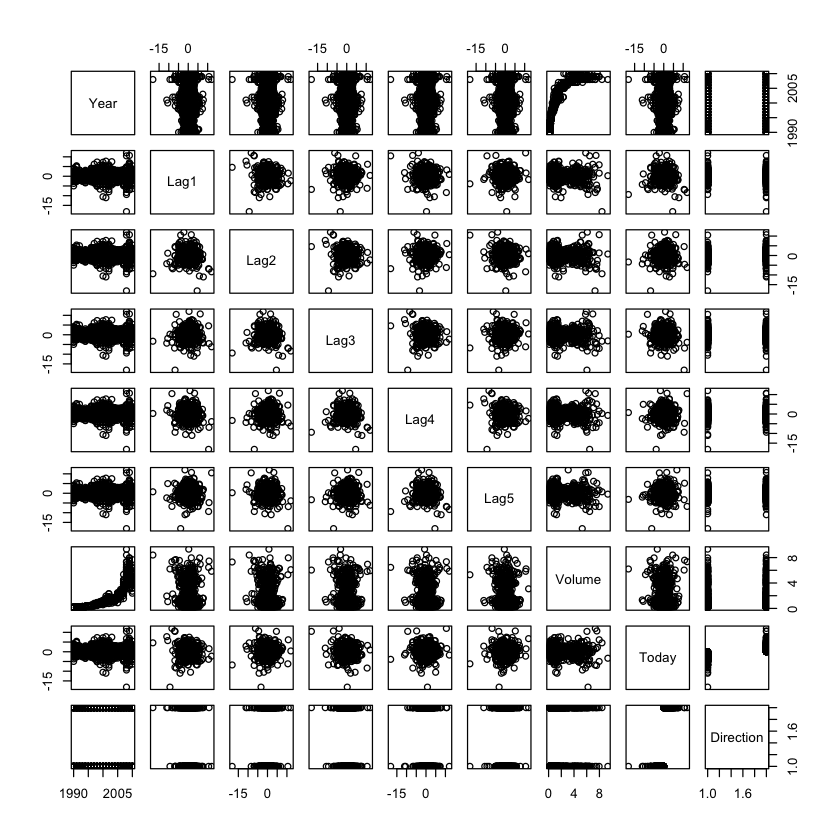

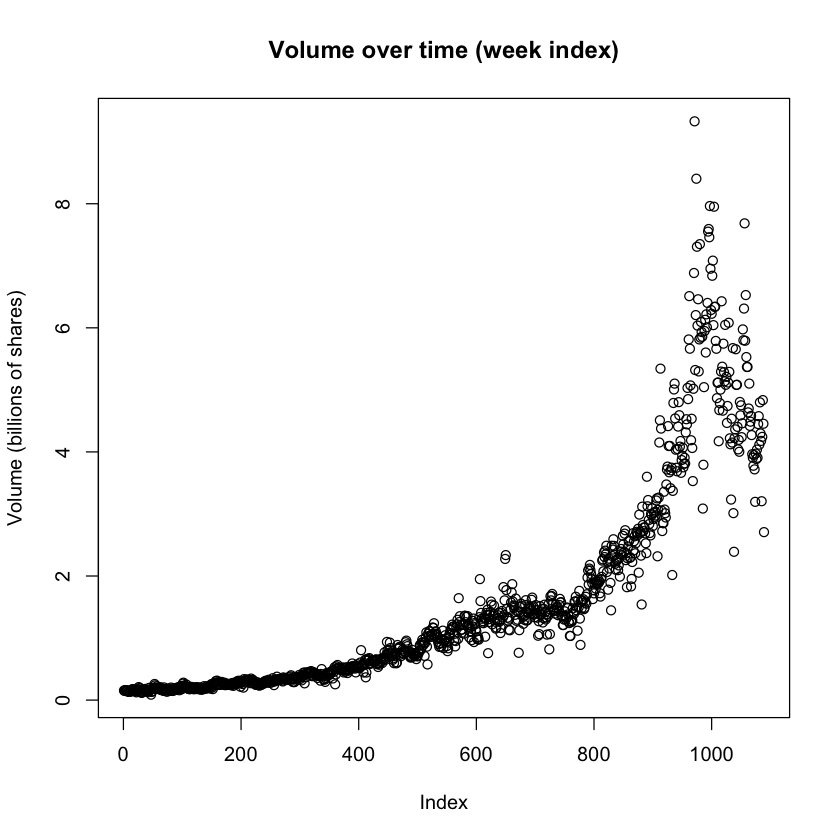


Down   Up 
 484  605 

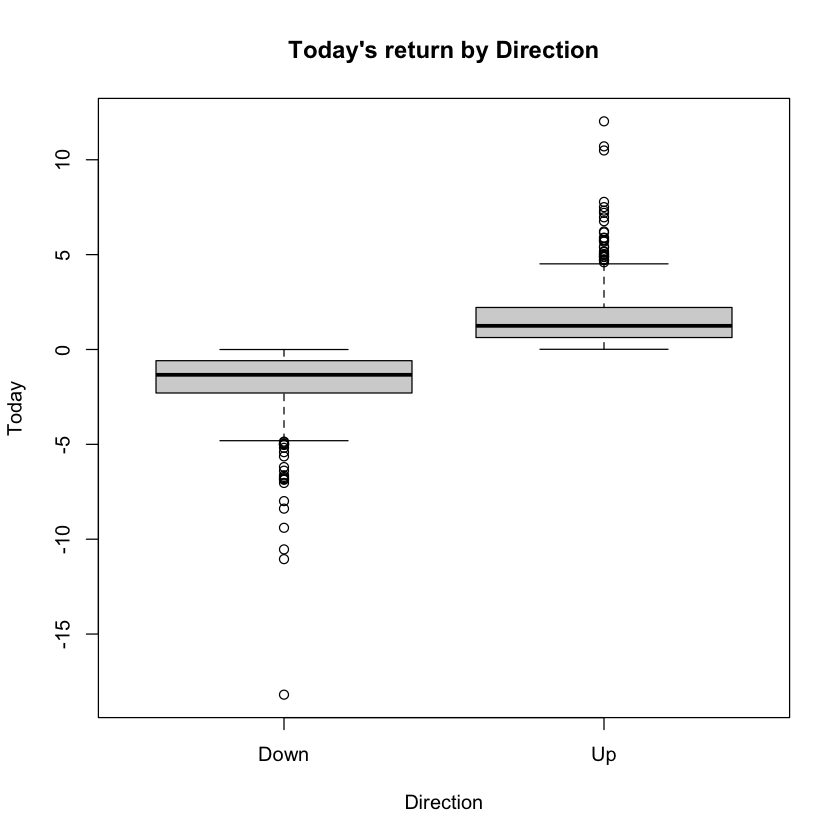

In [1]:
# Exercise 10 (a) Numerical and graphical summaries
library(ISLR)
library(MASS)
library(class)

names(Weekly)
dim(Weekly)
summary(Weekly)

# Pairwise correlations among the numeric variables (Direction is column 9)
cor(Weekly[, -9])

# Graphical summaries
pairs(Weekly)
plot(Weekly$Volume, ylab = "Volume (billions of shares)", main = "Volume over time (week index)")
boxplot(Today ~ Direction, data = Weekly, main = "Today's return by Direction")
table(Weekly$Direction)

In [2]:
# (b) Logistic regression on the full data set
glm.fit <- glm(Direction ~ Lag1 + Lag2 + Lag3 + Lag4 + Lag5 + Volume,
               data = Weekly, family = binomial)
summary(glm.fit)


Call:
glm(formula = Direction ~ Lag1 + Lag2 + Lag3 + Lag4 + Lag5 + 
    Volume, family = binomial, data = Weekly)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)   
(Intercept)  0.26686    0.08593   3.106   0.0019 **
Lag1        -0.04127    0.02641  -1.563   0.1181   
Lag2         0.05844    0.02686   2.175   0.0296 * 
Lag3        -0.01606    0.02666  -0.602   0.5469   
Lag4        -0.02779    0.02646  -1.050   0.2937   
Lag5        -0.01447    0.02638  -0.549   0.5833   
Volume      -0.02274    0.03690  -0.616   0.5377   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 1496.2  on 1088  degrees of freedom
Residual deviance: 1486.4  on 1082  degrees of freedom
AIC: 1500.4

Number of Fisher Scoring iterations: 4


In [3]:
# (c) Confusion matrix and overall fraction of correct predictions
glm.probs <- predict(glm.fit, type = "response")
glm.pred.full <- ifelse(glm.probs > 0.5, "Up", "Down")
table(glm.pred.full, Weekly$Direction)
mean(glm.pred.full == Weekly$Direction)

             
glm.pred.full Down  Up
         Down   54  48
         Up    430 557

[1] 0.5610652

In [4]:
# (d) Logistic regression, train 1990-2008, Lag2 only; evaluate on 2009-2010
train <- Weekly$Year < 2009
Weekly.test <- Weekly[!train, ]
Direction.train <- Weekly$Direction[train]
Direction.test  <- Weekly$Direction[!train]

glm.fit2 <- glm(Direction ~ Lag2, data = Weekly, family = binomial, subset = train)
glm.probs2 <- predict(glm.fit2, Weekly.test, type = "response")
glm.pred <- ifelse(glm.probs2 > 0.5, "Up", "Down")
table(glm.pred, Direction.test)
mean(glm.pred == Direction.test)

        Direction.test
glm.pred Down Up
    Down    9  5
    Up     34 56

[1] 0.625